In [2]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from collections import defaultdict
import random
import os

seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

img_width, img_height = 100, 100
batch_size = 512
AUTOTUNE = tf.data.AUTOTUNE

tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]
immune_folders = ["CD4+_T_Cells", "CD8+_T_Cells", "B_Cells", "Stromal"]
sub_label_list = tumour_folders + immune_folders
sub_label_to_index = {name: idx for idx, name in enumerate(sub_label_list)}

def get_file_label_pairs(folders, main_label):
    pairs = []
    for folder in folders:
        files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
        for f in files:
            sub_label = os.path.basename(folder)
            pairs.append((f, main_label, sub_label))
    return pairs

tumour_files = get_file_label_pairs(tumour_folders, main_label=1)
immune_files = get_file_label_pairs(immune_folders, main_label=0)
all_file_label_pairs = tumour_files + immune_files
print(f"Total images before balancing: {len(all_file_label_pairs)}")

def create_balanced_equal_dataset(file_label_pairs, target_size=15000):
    label_to_files = defaultdict(list)
    for f, main_label, sub_label in file_label_pairs:
        label_to_files[sub_label].append((f, main_label, sub_label))

    balanced = []
    for sub_label, files in label_to_files.items():
        originals = files.copy()
        current_size = len(originals)

        if current_size < target_size:
            extra_needed = target_size - current_size
            oversampled_files = random.choices(originals, k=extra_needed)
            balanced.extend((f, m, s, False) for f, m, s in originals)
            balanced.extend((f, m, s, True) for f, m, s in oversampled_files)
        elif current_size > target_size:
            undersampled_files = random.sample(originals, k=target_size)
            balanced.extend((f, m, s, False) for f, m, s in undersampled_files)
        else:
            balanced.extend((f, m, s, False) for f, m, s in originals)

    random.shuffle(balanced)
    return balanced

target_size = 15000
balanced_pairs = create_balanced_equal_dataset(all_file_label_pairs, target_size = target_size)
print(f"Total images each class balances to: {target_size}")
print(f"Total images after balancing: {len(balanced_pairs)}")

def augment_image(img):
    angles = [0, 90, 180, 270]
    angle = random.choice(angles)
    
    if angle == 90:
        img = tf.image.rot90(img, k=1)
    elif angle == 180:
        img = tf.image.rot90(img, k=2)
    elif angle == 270:
        img = tf.image.rot90(img, k=3)

    flip_type = random.choice(['none', 'horizontal', 'vertical', 'both'])
    if flip_type == 'horizontal':
        img = tf.image.flip_left_right(img)
    elif flip_type == 'vertical':
        img = tf.image.flip_up_down(img)
    elif flip_type == 'both':
        img = tf.image.flip_left_right(img)
        img = tf.image.flip_up_down(img)

    return img

def decode_img(img_path, augment=False):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [img_width, img_height])
    img = img / 255.0
    if augment:
        img = augment_image(img)
    return img

def prepare_dataset(pairs):
    file_paths, main_labels, sub_labels, augment_flags = [], [], [], []
    
    for f, m, s, a in pairs:
        file_paths.append(f)
        main_labels.append(m)
        sub_labels.append(sub_label_to_index[s])
        augment_flags.append(a)

    file_paths = np.array(file_paths)
    main_labels = np.array(main_labels)
    sub_labels = np.array(sub_labels)
    augment_flags = np.array(augment_flags)

    train_files, test_files, train_main, test_main, train_sub, test_sub, train_aug, test_aug = train_test_split(
        file_paths, main_labels, sub_labels, augment_flags, test_size=0.2, stratify=sub_labels, random_state=seed
    )

    def process_path(file_path, main_label, sub_label, augment):
        img = decode_img(file_path, augment)
        return img, {"binary_output": main_label, "multiclass_output": sub_label}

    train_ds = tf.data.Dataset.from_tensor_slices((train_files, train_main, train_sub, train_aug))
    train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE).shuffle(1000).batch(batch_size).prefetch(AUTOTUNE)

    test_ds = tf.data.Dataset.from_tensor_slices((test_files, test_main, test_sub, test_aug))
    test_ds = test_ds.map(process_path, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

    return train_ds, test_ds

train_ds_over, test_ds_over = prepare_dataset(balanced_pairs)

def build_multitask_model():
    inputs = tf.keras.Input(shape=(img_width, img_height, 3))
    x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)
    x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)

    binary_output = tf.keras.layers.Dense(1, activation='sigmoid', name="binary_output")(x)
    multiclass_logits = tf.keras.layers.Dense(8, name="raw_multiclass_logits")(x)
    scaled_logits = tf.keras.layers.Multiply()([multiclass_logits, binary_output])
    multiclass_output = tf.keras.layers.Activation('softmax', name="multiclass_output")(scaled_logits)

    model = tf.keras.Model(inputs=inputs, outputs=[binary_output, multiclass_output])

    model.compile(
        optimizer='adam',
        loss={
            "binary_output": "binary_crossentropy",
            "multiclass_output": "sparse_categorical_crossentropy"
        },
        metrics={
            "binary_output": "accuracy",
            "multiclass_output": "accuracy"
        }
    )

    return model

Total images before balancing: 91224
Total images each class balances to: 15000
Total images after balancing: 120000


In [5]:
def build_model():
    inputs = tf.keras.Input(shape=(img_width, img_height, 3))
    x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)
    x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu')(x)
    x = tf.keras.layers.MaxPooling2D((2, 2))(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)

    binary_output = tf.keras.layers.Dense(1, activation='sigmoid', name="binary_output")(x)
    multiclass_output = tf.keras.layers.Dense(8, activation='softmax', name="multiclass_output")(x)

    model = tf.keras.Model(inputs=inputs, outputs=[binary_output, multiclass_output])
    model.compile(
        optimizer='adam',
        loss={
            "binary_output": "binary_crossentropy",
            "multiclass_output": "sparse_categorical_crossentropy"
        },
        metrics={
            "binary_output": "accuracy",
            "multiclass_output": "accuracy"
        }
    )
    return model

In [6]:
model = build_model()

history = model.fit(
    train_ds_over,
    validation_data=test_ds_over,
    epochs=15
)

Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 187s 989ms/step - binary_output_accuracy: 0.6793 - binary_output_loss: 0.5805 - loss: 2.9199 - multiclass_output_accuracy: 0.2020 - multiclass_output_loss: 2.3394 - val_binary_output_accuracy: 0.8451 - val_binary_output_loss: 0.3844 - val_loss: 2.0421 - val_multiclass_output_accuracy: 0.3296 - val_multiclass_output_loss: 1.6575
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 181s 962ms/step - binary_output_accuracy: 0.8638 - binary_output_loss: 0.3362 - loss: 1.9025 - multiclass_output_accuracy: 0.3672 - multiclass_output_loss: 1.5663 - val_binary_output_accuracy: 0.8505 - val_binary_output_loss: 0.3745 - val_loss: 1.9143 - val_multiclass_output_accuracy: 0.3965 - val_multiclass_output_loss: 1.5396
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 181s 959ms/step - binary_output_accuracy: 0.8732 - binary_output_loss: 0.3142 - loss: 1.7727 - multiclass_output_accuracy: 0.4181 - multiclass_output_loss: 1.4585 - val_binary_output_accuracy: 0.8771 - val_binary_output_

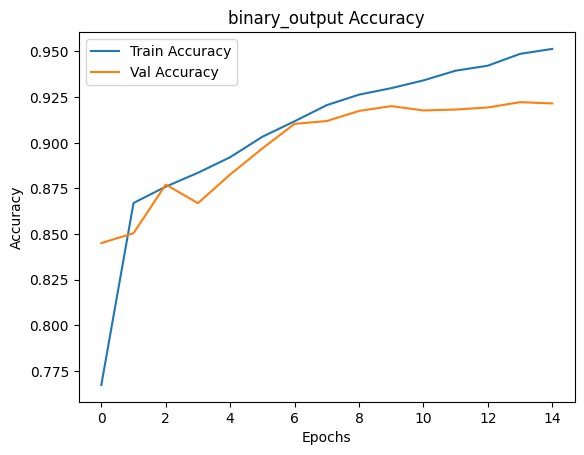

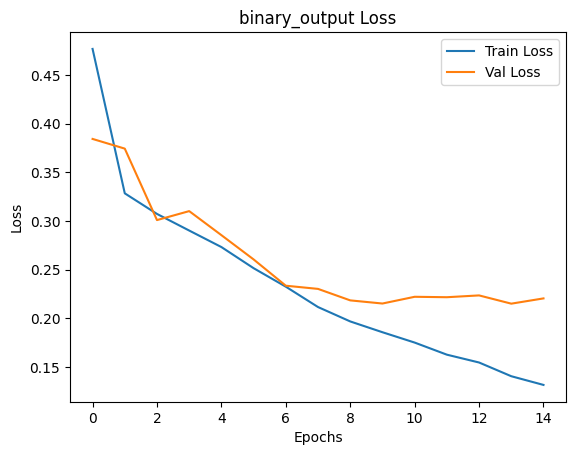

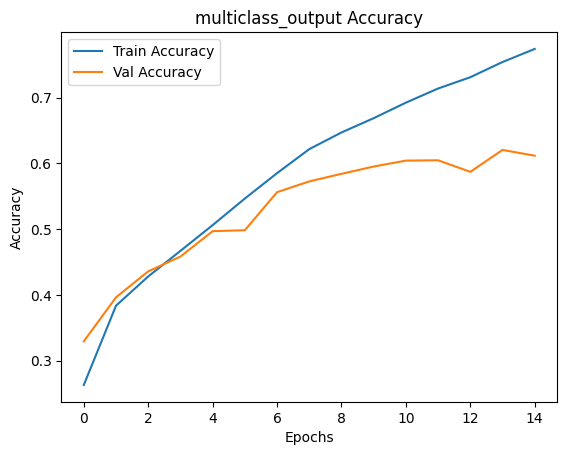

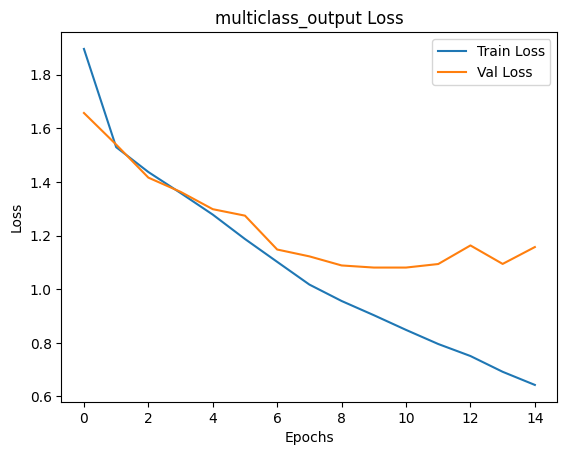

In [7]:
import matplotlib.pyplot as plt

def plot_history(history):
    for output in ['binary_output', 'multiclass_output']:
        plt.figure()
        plt.plot(history.history[f'{output}_accuracy'], label='Train Accuracy')
        plt.plot(history.history[f'val_{output}_accuracy'], label='Val Accuracy')
        plt.title(f'{output} Accuracy')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.show()

        plt.figure()
        plt.plot(history.history[f'{output}_loss'], label='Train Loss')
        plt.plot(history.history[f'val_{output}_loss'], label='Val Loss')
        plt.title(f'{output} Loss')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()

plot_history(history)

Binary Classification Report:
              precision    recall  f1-score   support

      Immune       0.93      0.91      0.92     12000
      Tumour       0.92      0.93      0.92     12000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



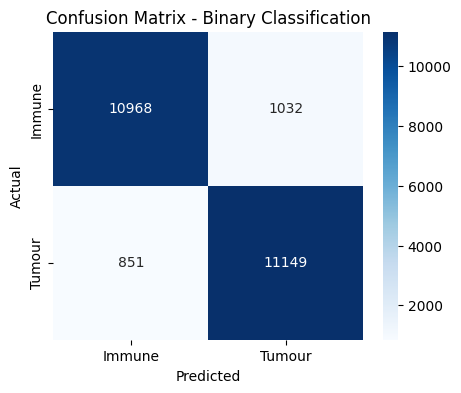

Multiclass Classification Report:
                       precision    recall  f1-score   support

       Invasive_Tumor       0.87      0.94      0.90      3000
               DCIS_1       0.73      0.81      0.77      3000
               DCIS_2       0.62      0.68      0.65      3000
Prolif_Invasive_Tumor       0.82      0.62      0.70      3000
         CD4+_T_Cells       0.46      0.47      0.47      3000
         CD8+_T_Cells       0.38      0.41      0.40      3000
              B_Cells       0.59      0.38      0.46      3000
              Stromal       0.47      0.58      0.52      3000

             accuracy                           0.61     24000
            macro avg       0.62      0.61      0.61     24000
         weighted avg       0.62      0.61      0.61     24000



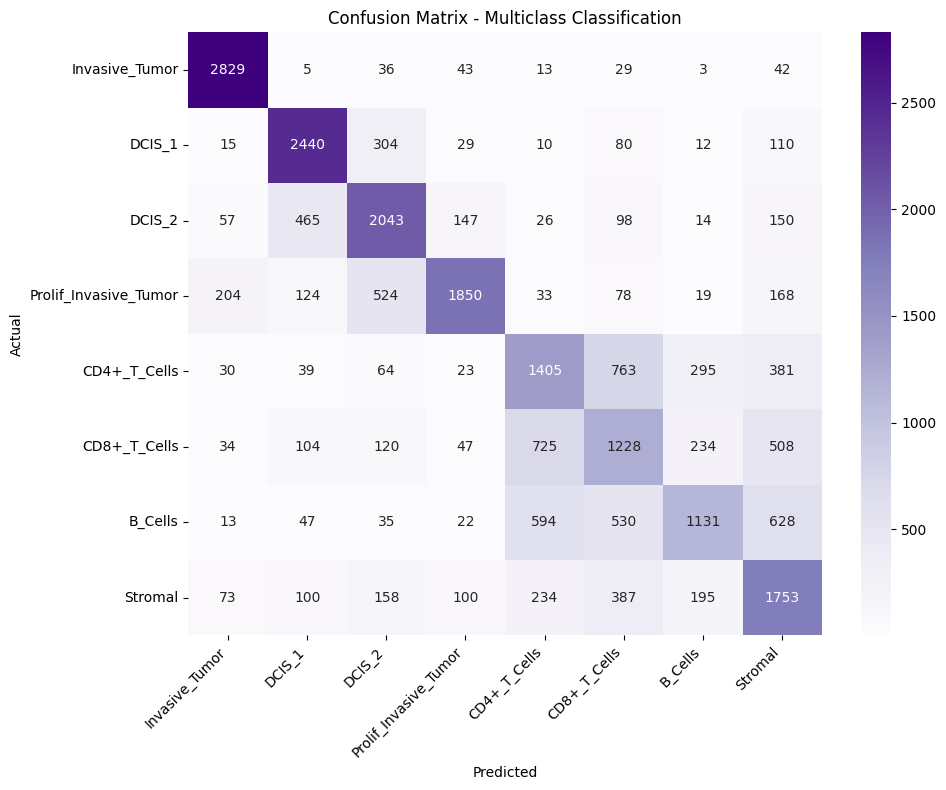

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("Binary Classification Report:")
print(classification_report(y_true_binary, y_pred_binary, target_names=["Immune", "Tumour"]))

cm_binary = confusion_matrix(y_true_binary, y_pred_binary)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_binary, annot=True, fmt='d', cmap='Blues', xticklabels=["Immune", "Tumour"], yticklabels=["Immune", "Tumour"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Binary Classification")
plt.show()

print("Multiclass Classification Report:")
print(classification_report(y_true_multiclass, y_pred_multiclass, target_names=sub_label_list))

cm_multi = confusion_matrix(y_true_multiclass, y_pred_multiclass)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Purples', xticklabels=sub_label_list, yticklabels=sub_label_list)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Multiclass Classification")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()